# 01｜ETF：先读懂已有实验，再讨论模型

研究问题：**增加动量和趋势过滤，是否同时改善收益与回撤？**

本机暂缺 1029 的原始 ETF 价格快照。本书用仓库已提交的真实验收摘要讲解和画图；不会从年化收益捏造日净值。本次读取摘要不等于本次重新回测。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 固定比较对象

五只基金是 SPY、QQQ、IWM、TLT、GLD。E0 为月度等权；E1 用过去 126 个交易日收益选前两只；E2 额外要求通过 200 日均线过滤，未通过的份额留现金。收盘后决定、下一交易日开盘执行。原实验采用碎股和单边 10 bps 的基础成本，不是 ML4Trading 的整股、每股佣金方案。

In [2]:
all_scores=load_frame("historical_results")
names=["E0","E1","E2","SPY_BH","ETF_CASH"]
scores=all_scores.set_index("experiment").loc[names]
display(scores[["fromDate","throughDate","annualReturn","maxDrawdown","sharpe","tradeCount"]])

,fromDate,throughDate,annualReturn,maxDrawdown,sharpe,tradeCount
experiment,,,,,,
E0,2007-02-01,2026-10-23,0.102321,-0.316436,0.821962,1190
E1,2007-02-01,2026-10-23,0.107347,-0.313513,0.718052,584
E2,2007-02-01,2026-10-23,0.095329,-0.351988,0.694509,546
SPY_BH,2007-02-01,2026-10-23,0.108051,-0.552011,0.622561,2
ETF_CASH,2007-02-01,2026-10-23,0.000000,0.000000,0.000000,0


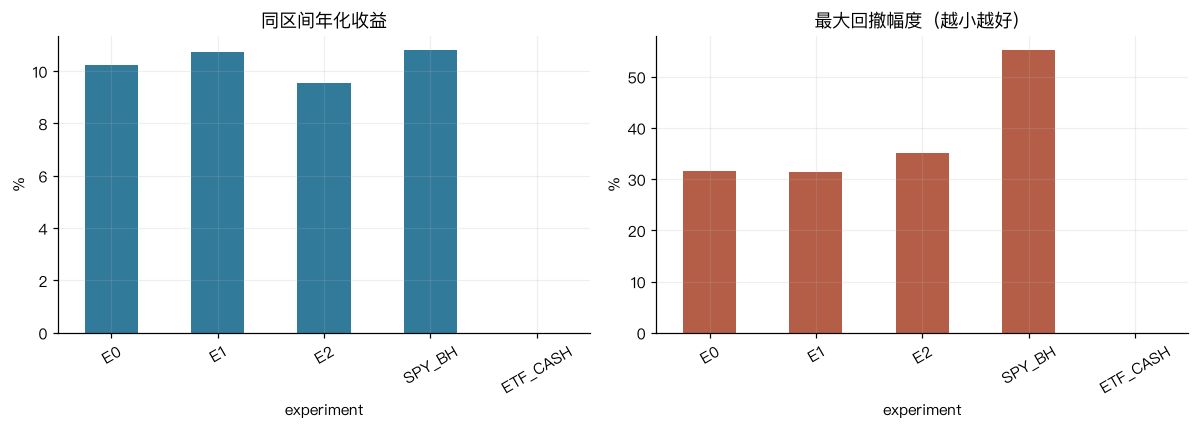

In [3]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
(scores.annualReturn*100).plot.bar(ax=axs[0],color="#317a9a",title="同区间年化收益")
(-scores.maxDrawdown*100).plot.bar(ax=axs[1],color="#b45e48",title="最大回撤幅度（越小越好）")
for ax in axs: ax.set_ylabel("%"); ax.tick_params(axis="x",rotation=30)
plt.tight_layout(); plt.show()

**读图：** 必须同时看两幅图。提高回报与减少回撤是两个不同目标；最高收益不一定对应最小风险。SPY 是股票基准，五资产组合包含债券与黄金；表现差异包含风险暴露差异，不能全部归因于信号。现金零收益只是一项明确假设。

## 2. 费用不是脚注

成本乘数 0、1、2 使用相同规则与样本。需要比较策略的斜率，而不是只展示零成本最好的一次。下面的代码没有挑最优参数，它把已保存的三个版本都展示出来。

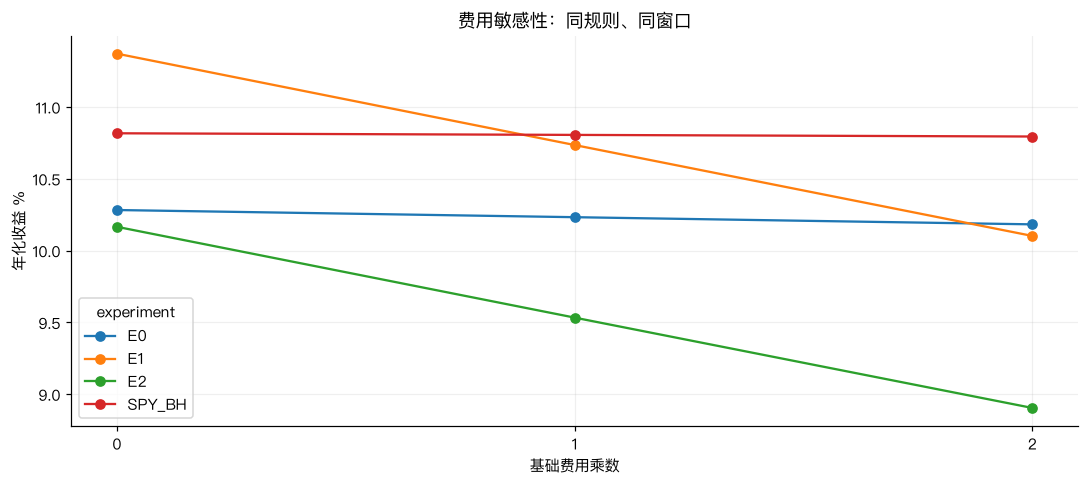

experiment
E0       -0.000998
E1       -0.012692
E2       -0.012614
SPY_BH   -0.000225
Name: 双倍费用相对零费用的年化变化, dtype: float64

In [4]:
costs=load_frame("historical_costs")
c=costs[costs.experiment.isin(["E0","E1","E2","SPY_BH"])].pivot(index="costMultiplier",columns="experiment",values="annualReturn")
(c*100).plot(marker="o",title="费用敏感性：同规则、同窗口")
plt.xlabel("基础费用乘数"); plt.ylabel("年化收益 %"); plt.xticks([0,1,2]); plt.tight_layout(); plt.show()
display((c.loc[2]-c.loc[0]).rename("双倍费用相对零费用的年化变化"))

## 3. 代码实际在哪里

调用链是 `target_weights → rebalance → simulate → metrics`。`target_weights` 只接收执行日以前的收盘；`rebalance` 从实际成交额扣费；`simulate` 保存逐日资金、权重和交易；`metrics` 使用同一资本与年化天数。下面直接查看现有函数，不另造第二个回测器。

In [5]:
import inspect
from tools.plan_1029_research import target_weights
print(inspect.getsource(target_weights))

def target_weights(history, rule):
    """只接收执行日前的收盘；过滤后份额留现金，不重新补选。"""
    names = list(history.columns)
    out = pd.Series(0.0, index=names)
    if rule == "cash":
        return out
    if rule == "hold":
        out.iloc[0] = 1
        return out
    if rule in ["equal", "weekly_equal"]:
        out[:] = 1 / len(names)
        return out
    if rule == "trend":
        if len(history) < 200:
            return out
        out.iloc[0] = float(history.iloc[-1, 0] > history.iloc[-200:, 0].mean())
        return out
    window = 90 if rule == "rotation" else 126
    if len(history) < max(window + 1, 200 if rule == "momentum_trend" else 0):
        return out
    scores = history.iloc[-1] / history.iloc[-window - 1] - 1
    chosen = sorted(names, key=lambda x: (-scores[x], x))[
        : 1 if rule == "rotation" else 2
    ]
    for name in chosen:
        if (
            rule != "momentum_trend"
            or history.iloc[-1][name] >= history.iloc[-200:][name].mean()
        ):
     

## 4. 导入原快照后的完整重算

把原运行环境的 `inputs/` 导入配置指定位置，保留 `audit.json`、`company-actions-verified.json`、`calendar.json`、三个价格 Parquet 和各自 `*-input.json`。`RESEARCH_EQUITY_INPUTS` 可覆盖教学准备器的导入位置。准备器校验原 Parquet SHA-256；全流程回放器还核对原验收与公司行动凭证。

在仓库根目录执行：
```sh
var/research-playbook-env/bin/python tools/plan_1029_research.py \
  --inputs var/plan-1029/20261030/inputs \
  --output var/research-playbook/replays
```

这是恢复旧实验的入口。修改策略、窗口或供应商就属于新实验，不能沿用旧结果身份。

In [6]:
display(inventory().set_index("dataset").loc[["etf_daily","historical_results"],["status","scope","reason"]].fillna("—"))

,status,scope,reason
dataset,,,
etf_daily,blocked,—,本机没有1029原价格快照；历史结果可读，逐日重算等待导入
historical_results,ready,2026-10-30已提交验收摘要；不是本次重新执行ETF/ETH回放,—


## 5. 本次能得出的结论

这套数据已经足以讲清基线、成本与回撤的关系。它不能证明 E1/E2 在未来会优于 E0，也不能证明 2024 年以后是从未见过的留出样本。下一步先拿到原快照、检查逐年和逐笔贡献，再决定是否加入模型。

**练习：** 如果选择 E1 的原因只是它在这张图上收益最好，为什么不能再用同一段历史宣称选择成功？因为这段历史已经参与选择，评估需要新的未见数据。

参考：[本项目原结果](../../docs/plan/1029/results.md)、[ML4T ETF 案例](https://github.com/stefan-jansen/machine-learning-for-trading/tree/main/case_studies/etfs)。